# CSET485 – AI and Society 
Harshith Akhilesh

S24CSEU1518

In [1]:
import os
import json
import warnings
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')

SEED = 518
os.makedirs('figures', exist_ok=True)
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

results = {}

DATA_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data'
DATA_FILE = 'adult.data'
if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

columns = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income',
]
raw = pd.read_csv(DATA_FILE, names=columns, skipinitialspace=True)
print('Rows, columns:', raw.shape)

Rows, columns: (32561, 15)


In [2]:
missing = (raw == '?').sum()
missing = missing[missing > 0]
rows_with_missing = int((raw == '?').any(axis=1).sum())

results['n_rows'] = int(len(raw))
results['missing'] = {col: int(n) for col, n in missing.items()}
results['missing_rows_any'] = rows_with_missing
results['missing_rows_any_pct'] = float(rows_with_missing / len(raw) * 100)
results['duplicates'] = int(raw.duplicated().sum())
results['prevalence'] = float((raw.income == '>50K').mean())
results['never_worked_without_pay'] = int(raw.workclass.isin(['Never-worked', 'Without-pay']).sum())
results['n_cap_gain_nonzero'] = int((raw['capital-gain'] > 0).sum())
results['n_cap_gain_99999'] = int((raw['capital-gain'] == 99999).sum())
results['cap_gain_skew'] = float(raw['capital-gain'].skew())

iqr_outliers = {}
for col in ['age', 'hours-per-week', 'education-num']:
    q1, q3 = raw[col].quantile([.25, .75])
    iqr = q3 - q1
    too_low = raw[col] < q1 - 1.5 * iqr
    too_high = raw[col] > q3 + 1.5 * iqr
    iqr_outliers[col] = int((too_low | too_high).sum())
results['iqr_outliers'] = iqr_outliers

print('Missing "?" by column:', results['missing'], '| rows with any missing:', results['missing_rows_any'], f"({results['missing_rows_any_pct']:.1f}%)")
print('Duplicates:', results['duplicates'], '| positive rate (>50K):', round(results['prevalence'], 4))
print('capital-gain nonzero:', results['n_cap_gain_nonzero'], '| top-coded 99999:', results['n_cap_gain_99999'], '| skew:', round(results['cap_gain_skew'], 1))
print('IQR outliers:', iqr_outliers)

Missing "?" by column: {'workclass': 1836, 'occupation': 1843, 'native-country': 583} | rows with any missing: 2399 (7.4%)
Duplicates: 24 | positive rate (>50K): 0.2408
capital-gain nonzero: 2712 | top-coded 99999: 159 | skew: 12.0
IQR outliers: {'age': 143, 'hours-per-week': 9008, 'education-num': 1198}


In [3]:
y = (raw.income == '>50K').astype(int)
X = raw.drop(columns=['income', 'fnlwgt', 'education', 'relationship']).copy()

no_job_info = ['?', 'Never-worked', 'Without-pay']
X['job_info_missing'] = (X.workclass.isin(no_job_info) | (X.occupation == '?')).astype(float)

country = X['native-country']
X['native-country'] = np.where(country == 'United-States', 'US',
                               np.where(country == '?', 'Unknown', 'Non-US'))

X['marital-status'] = X['marital-status'].replace({'Married-AF-spouse': 'Married-civ-spouse'})
X['occupation'] = X.occupation.replace({'Armed-Forces': 'Protective-serv', 'Priv-house-serv': 'Other-service'})

X['capital-gain'] = np.log1p(X['capital-gain'])
X['capital-loss'] = np.log1p(X['capital-loss'])
num_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED)
results['n_train'] = int(len(X_train))
results['n_test'] = int(len(X_test))

for col in ['workclass', 'occupation']:
    valid = ~X_train[col].isin(no_job_info)
    mode = X_train.loc[valid, col].mode()[0]
    for part in (X_train, X_test):
        part[col] = part[col].replace({'?': mode, 'Never-worked': mode, 'Without-pay': mode})
    print(f'{col}: missing imputed with train mode = {mode}')

lower = X_train[num_cols].quantile(.01)
upper = X_train[num_cols].quantile(.99)
for part in (X_train, X_test):
    part[num_cols] = part[num_cols].clip(lower, upper, axis=1)

train_mean = X_train[num_cols].mean()
train_sd = X_train[num_cols].std(ddof=0)
for part in (X_train, X_test):
    part[num_cols] = (part[num_cols] - train_mean) / train_sd

results['scaling'] = {
    col: {'p01': float(lower[col]), 'p99': float(upper[col]),
          'mean': float(train_mean[col]), 'sd': float(train_sd[col])}
    for col in num_cols
}

cat_cols = ['workclass', 'marital-status', 'occupation', 'race', 'sex', 'native-country']
base_level = {col: X_train[col].value_counts().index[0] for col in cat_cols}
base_level['sex'] = 'Female'

def one_hot(df):
    out = df[num_cols + ['job_info_missing']].copy()
    for col in cat_cols:
        for level in sorted(X_train[col].unique()):
            if level != base_level[col]:
                out[f'{col}_{level}'] = (df[col] == level).astype(float)
    return out

E_train = one_hot(X_train)
E_test = one_hot(X_test)
results['n_features'] = int(E_train.shape[1])
results['base_levels'] = base_level

print('Reference levels:', base_level)
print('Train', E_train.shape, 'Test', E_test.shape, '| train positive rate', round(y_train.mean(), 4), '| test positive rate', round(y_test.mean(), 4))
results['train_pos_rate'] = float(y_train.mean())
results['test_pos_rate'] = float(y_test.mean())

y_true = y_test.values
raw_test = raw.loc[X_test.index].reset_index(drop=True)
raw_train = raw.loc[X_train.index].reset_index(drop=True)

workclass: missing imputed with train mode = Private
occupation: missing imputed with train mode = Prof-specialty
Reference levels: {'workclass': 'Private', 'marital-status': 'Married-civ-spouse', 'occupation': 'Prof-specialty', 'race': 'White', 'sex': 'Female', 'native-country': 'US'}
Train (22792, 34) Test (9769, 34) | train positive rate 0.2405 | test positive rate 0.2415


In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def fit_logit(features, target, max_iter=100):
    A = np.column_stack([np.ones(len(features)), features.values.astype(float)])
    target = np.asarray(target, float)
    beta = np.zeros(A.shape[1])

    for _ in range(max_iter):
        p = sigmoid(A @ beta)
        hessian = A.T @ (A * (p * (1 - p))[:, None])
        new_beta = beta + np.linalg.solve(hessian, A.T @ (target - p))
        if np.max(np.abs(new_beta - beta)) < 1e-10:
            beta = new_beta
            break
        beta = new_beta

    p = sigmoid(A @ beta)
    hessian = A.T @ (A * (p * (1 - p))[:, None])
    se = np.sqrt(np.diag(np.linalg.inv(hessian)))
    z = beta / se

    return pd.DataFrame({
        'coef': beta,
        'se': se,
        'z': z,
        'p': 2 * stats.norm.sf(np.abs(z)),
        'lo': beta - 1.96 * se,
        'hi': beta + 1.96 * se,
    }, index=['const'] + list(features.columns))

def predict_logit(table, features):
    A = np.column_stack([np.ones(len(features)), features[table.index[1:]].values.astype(float)])
    return sigmoid(A @ table.coef.values)

full_logit = fit_logit(E_train, y_train)

sk_check = LogisticRegression(C=1e10, max_iter=10000, tol=1e-10).fit(E_train, y_train)
results['irls_vs_sklearn_maxdiff'] = float(np.max(np.abs(sk_check.coef_[0] - full_logit.coef.values[1:])))
print('max |IRLS - sklearn| coefficient difference:', results['irls_vs_sklearn_maxdiff'])
print('largest standard error in full model:', round(full_logit.se.max(), 3), '(no separation problems)')
full_logit.round(3)

max |IRLS - sklearn| coefficient difference: 1.469414336563446e-05
largest standard error in full model: 0.305 (no separation problems)


,coef,se,z,p,lo,hi
const,-0.293,0.080,-3.650,0.000,-0.451,-0.136
age,0.357,0.026,14.004,0.000,0.307,0.407
education-num,0.729,0.027,26.824,0.000,0.675,0.782
capital-gain,0.489,0.019,26.419,0.000,0.453,0.525
capital-loss,0.235,0.018,13.215,0.000,0.200,0.270
hours-per-week,0.385,0.023,16.390,0.000,0.339,0.431
job_info_missing,-1.150,0.132,-8.740,0.000,-1.408,-0.892
workclass_Federal-gov,0.401,0.108,3.730,0.000,0.190,0.612
workclass_Local-gov,-0.158,0.082,-1.922,0.055,-0.319,0.003
workclass_Self-emp-inc,0.210,0.100,2.092,0.036,0.013,0.407


Model B (0.5 thr)     high   low
Model A (median thr)            
high                  1892  2993
low                      0  4884 

median_pA: 0.2250536894925247
n_test: 9769
cm: {'A_low_B_low': 4884, 'A_low_B_high': 0, 'A_high_B_low': 2993, 'A_high_B_high': 1892}
mismatch: 2993
mismatch_pct: 30.637731599959057
flag_rate_A: 0.5000511823113932
flag_rate_B: 0.19367386631180264
pA_min: -0.3436460020660277
pA_max: 1.0975532383349258
pA_below0: 2089
pA_above1: 28
frac_pA_ge_0p5: 0.17668133892926605
mean_pA: 0.24004184377287896
mean_pB: 0.2391536698433619
corr_pA_pB: 0.9384429588928559
spearman_pA_pB: 0.9842451641021229
auc_A: 0.895665150092762
auc_B: 0.899021177687428
acc_A: 0.711741222233596
acc_B: 0.8488074521445389
prec_A: 0.4532241555783009
prec_B: 0.7330866807610994
rec_A: 0.9385332768122086
rec_B: 0.5879610004239084
mismatch_A_at_0p5: 298
cut_matched_to_B_rate: 0.47868522320562634
mismatch_A_rate_matched: 264
mismatch_A_rate_matched_pct: 2.7024260415600367


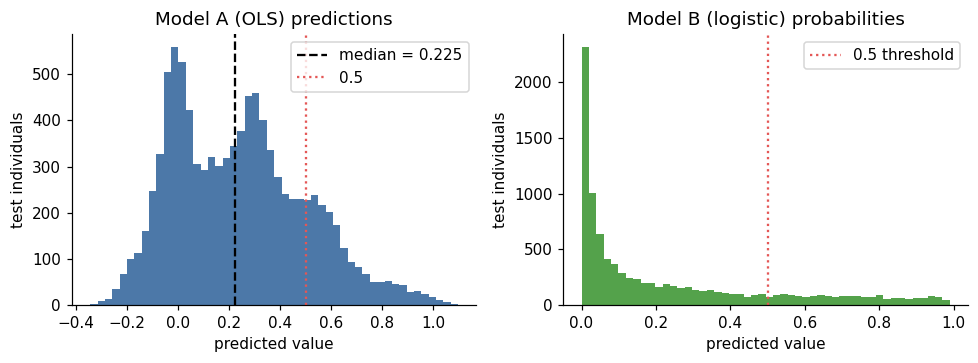

In [5]:
ols = LinearRegression().fit(E_train, y_train)
pred_ols = ols.predict(E_test)
pred_logit = predict_logit(full_logit, E_test)

median_ols = float(np.median(pred_ols))
flag_ols = (pred_ols >= median_ols).astype(int)
flag_logit = (pred_logit >= 0.5).astype(int)

label = {0: 'low', 1: 'high'}
confusion = pd.crosstab(pd.Series(flag_ols, name='Model A (median thr)').map(label),
                        pd.Series(flag_logit, name='Model B (0.5 thr)').map(label))
print(confusion, '\n')

n_mismatch = int((flag_ols != flag_logit).sum())

p1 = {
    'median_pA': median_ols,
    'n_test': int(len(pred_ols)),
    'cm': {
        'A_low_B_low': int(((flag_ols == 0) & (flag_logit == 0)).sum()),
        'A_low_B_high': int(((flag_ols == 0) & (flag_logit == 1)).sum()),
        'A_high_B_low': int(((flag_ols == 1) & (flag_logit == 0)).sum()),
        'A_high_B_high': int(((flag_ols == 1) & (flag_logit == 1)).sum()),
    },
    'mismatch': n_mismatch,
    'mismatch_pct': n_mismatch / len(pred_ols) * 100,
    'flag_rate_A': float(flag_ols.mean()),
    'flag_rate_B': float(flag_logit.mean()),
    'pA_min': float(pred_ols.min()),
    'pA_max': float(pred_ols.max()),
    'pA_below0': int((pred_ols < 0).sum()),
    'pA_above1': int((pred_ols > 1).sum()),
    'frac_pA_ge_0p5': float((pred_ols >= 0.5).mean()),
    'mean_pA': float(pred_ols.mean()),
    'mean_pB': float(pred_logit.mean()),
    'corr_pA_pB': float(np.corrcoef(pred_ols, pred_logit)[0, 1]),
    'spearman_pA_pB': float(stats.spearmanr(pred_ols, pred_logit)[0]),
    'auc_A': float(roc_auc_score(y_true, pred_ols)),
    'auc_B': float(roc_auc_score(y_true, pred_logit)),
    'acc_A': float((flag_ols == y_true).mean()),
    'acc_B': float((flag_logit == y_true).mean()),
    'prec_A': float(y_true[flag_ols == 1].mean()),
    'prec_B': float(y_true[flag_logit == 1].mean()),
    'rec_A': float(flag_ols[y_true == 1].mean()),
    'rec_B': float(flag_logit[y_true == 1].mean()),
}

p1['mismatch_A_at_0p5'] = int(((pred_ols >= 0.5).astype(int) != flag_logit).sum())
matched_cut = float(np.quantile(pred_ols, 1 - flag_logit.mean()))
p1['cut_matched_to_B_rate'] = matched_cut
p1['mismatch_A_rate_matched'] = int(((pred_ols >= matched_cut).astype(int) != flag_logit).sum())
p1['mismatch_A_rate_matched_pct'] = p1['mismatch_A_rate_matched'] / len(pred_ols) * 100

results['p1'] = p1
for key, value in p1.items():
    print(f'{key}: {value}')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].hist(pred_ols, bins=50, color='#4C78A8')
axes[0].axvline(median_ols, color='k', ls='--', label=f'median = {median_ols:.3f}')
axes[0].axvline(0.5, color='#E45756', ls=':', label='0.5')
axes[0].set_title('Model A (OLS) predictions')
axes[0].legend()

axes[1].hist(pred_logit, bins=50, color='#54A24B')
axes[1].axvline(0.5, color='#E45756', ls=':', label='0.5 threshold')
axes[1].set_title('Model B (logistic) probabilities')
axes[1].legend()

for ax in axes:
    ax.set_xlabel('predicted value')
    ax.set_ylabel('test individuals')
plt.tight_layout()
plt.savefig('figures/fig1_predictions.png', dpi=150)
plt.show()

subgroup sizes (train): married 10494 | unmarried 12298
largest SE: married 0.335 unmarried 0.74

sex_Male marginal (no controls): 1.283 [1.203, 1.363]
sex_Male        full  0.167 [ 0.050, 0.285] | married -0.375 [-0.531,-0.218] | unmarried  0.839 [ 0.644, 1.035] | z_diff  -9.50
age             full  0.357 [ 0.307, 0.407] | married  0.314 [ 0.258, 0.371] | unmarried  0.626 [ 0.512, 0.741] | z_diff  -4.79
education-num   full  0.729 [ 0.675, 0.782] | married  0.685 [ 0.626, 0.744] | unmarried  0.835 [ 0.713, 0.958] | z_diff  -2.17
hours-per-week  full  0.385 [ 0.339, 0.431] | married  0.347 [ 0.293, 0.400] | unmarried  0.552 [ 0.459, 0.645] | z_diff  -3.75
capital-gain    full  0.489 [ 0.453, 0.525] | married  0.397 [ 0.355, 0.439] | unmarried  0.668 [ 0.604, 0.733] | z_diff  -6.91

raw >50K rates: {'male': 0.306, 'female': 0.109, 'male_married': 0.447, 'female_married': 0.459, 'male_unmarried': 0.085, 'female_unmarried': 0.043} 
share married: {'male': 0.61, 'female': 0.157}
age split:

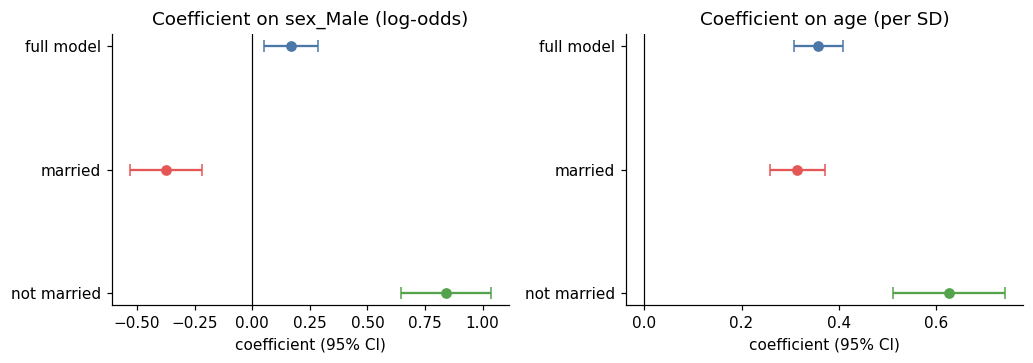

In [6]:
marital_cols = [c for c in E_train.columns if c.startswith('marital-status_')]
is_married = (E_train[marital_cols].sum(axis=1) == 0).values

def fit_subgroup(mask, drop=()):
    sub = E_train.loc[mask].drop(columns=list(drop))
    sub = sub.loc[:, sub.nunique() > 1]
    return fit_logit(sub, y_train[mask])

sub_married = fit_subgroup(is_married)
sub_unmarried = fit_subgroup(~is_married, drop=['marital-status_Never-married'])
print('subgroup sizes (train): married', int(is_married.sum()), '| unmarried', int((~is_married).sum()))
print('largest SE: married', round(sub_married.se.max(), 3), 'unmarried', round(sub_unmarried.se.max(), 3))

predictors = ['sex_Male', 'age', 'education-num', 'hours-per-week', 'capital-gain']
rows = []
for name in predictors:
    entry = {'predictor': name}
    for key, table in (('full', full_logit), ('married', sub_married), ('unmarried', sub_unmarried)):
        entry[key] = {k: float(table.loc[name, k]) for k in ('coef', 'se', 'lo', 'hi', 'p')}
    diff = sub_married.loc[name, 'coef'] - sub_unmarried.loc[name, 'coef']
    entry['z_diff'] = float(diff / np.sqrt(sub_married.loc[name, 'se'] ** 2 + sub_unmarried.loc[name, 'se'] ** 2))
    entry['p_diff'] = float(2 * stats.norm.sf(abs(entry['z_diff'])))
    rows.append(entry)

marginal = fit_logit(E_train[['sex_Male']], y_train).loc['sex_Male']

simpson = {
    'rows': rows,
    'n_married': int(is_married.sum()),
    'n_unmarried': int((~is_married).sum()),
    'marginal_sex': {k: float(marginal[k]) for k in ('coef', 'se', 'lo', 'hi')},
}

train_view = raw_train.copy()
train_view['y'] = y_train.values
train_view['married'] = is_married
train_view['male'] = train_view.sex == 'Male'
male, married = train_view.male, train_view.married

simpson['raw_rate'] = {
    'male': float(train_view[male].y.mean()),
    'female': float(train_view[~male].y.mean()),
    'male_married': float(train_view[male & married].y.mean()),
    'female_married': float(train_view[~male & married].y.mean()),
    'male_unmarried': float(train_view[male & ~married].y.mean()),
    'female_unmarried': float(train_view[~male & ~married].y.mean()),
}
simpson['share_married'] = {
    'male': float(train_view[male].married.mean()),
    'female': float(train_view[~male].married.mean()),
}
simpson['rate_married'] = float(train_view[married].y.mean())
simpson['rate_unmarried'] = float(train_view[~married].y.mean())
simpson['n_male_married'] = int((male & married).sum())
simpson['n_female_married'] = int((~male & married).sum())

is_40_plus = (raw_train.age >= 40).values
sub_40_plus = fit_subgroup(is_40_plus)
sub_under_40 = fit_subgroup(~is_40_plus)
simpson['age_split'] = {
    'n_40plus': int(is_40_plus.sum()),
    'n_under40': int((~is_40_plus).sum()),
    'full': {k: float(full_logit.loc['age', k]) for k in ('coef', 'lo', 'hi')},
    'age40plus': {k: float(sub_40_plus.loc['age', k]) for k in ('coef', 'lo', 'hi')},
    'under40': {k: float(sub_under_40.loc['age', k]) for k in ('coef', 'lo', 'hi')},
}
results['simpson'] = simpson

print('\nsex_Male marginal (no controls): %.3f [%.3f, %.3f]' % (marginal.coef, marginal.lo, marginal.hi))
for d in rows:
    print(f"{d['predictor']:15s} full {d['full']['coef']:6.3f} [{d['full']['lo']:6.3f},{d['full']['hi']:6.3f}] | "
          f"married {d['married']['coef']:6.3f} [{d['married']['lo']:6.3f},{d['married']['hi']:6.3f}] | "
          f"unmarried {d['unmarried']['coef']:6.3f} [{d['unmarried']['lo']:6.3f},{d['unmarried']['hi']:6.3f}] | z_diff {d['z_diff']:6.2f}")
print('\nraw >50K rates:', {k: round(v, 3) for k, v in simpson['raw_rate'].items()},
      '\nshare married:', {k: round(v, 3) for k, v in simpson['share_married'].items()})
print('age split:', simpson['age_split'])

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
panels = [('sex_Male', 'Coefficient on sex_Male (log-odds)'), ('age', 'Coefficient on age (per SD)')]
colors = [('full', '#4C78A8'), ('married', '#E45756'), ('unmarried', '#54A24B')]
for ax, (name, title) in zip(axes, panels):
    entry = [r for r in rows if r['predictor'] == name][0]
    for pos, (key, color) in enumerate(colors):
        coef, lo, hi = entry[key]['coef'], entry[key]['lo'], entry[key]['hi']
        ax.errorbar(coef, pos, xerr=[[coef - lo], [hi - coef]], fmt='o', color=color, capsize=4)
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(['full model', 'married', 'not married'])
    ax.invert_yaxis()
    ax.axvline(0, color='k', lw=.8)
    ax.set_title(title)
    ax.set_xlabel('coefficient (95% CI)')
plt.tight_layout()
plt.savefig('figures/fig2_simpson.png', dpi=150)
plt.show()

                 full  reduced    chg      pct
sex_Male        0.167    1.129  0.962  575.852
age             0.357    0.581  0.223   62.551
hours-per-week  0.385    0.394  0.009    2.312
education-num   0.729    0.662 -0.067   -9.151
capital-gain    0.489    0.477 -0.012   -2.449
capital-loss    0.235    0.240  0.005    2.143 

Largest % shifts:
                          full  reduced      pct
sex_Male                 0.167    1.129  575.852
race_Black              -0.141   -0.360 -155.168
workclass_Local-gov     -0.158   -0.057   64.228
age                      0.357    0.581   62.551
race_Asian-Pac-Islander -0.082   -0.032   61.555
workclass_Self-emp-inc   0.210    0.336   59.859

Aggregate metrics full vs reduced: acc 0.8488 vs 0.8258 | AUC 0.8990 vs 0.8585
Residual correlation with married flag (test): reduced 0.269, full -0.002
Calibration by marital group: {'married': {'obs': 0.444173140954495, 'pred_reduced': 0.3413630490648552, 'pred_full': 0.4424922585804415}, 'unmarried': {'

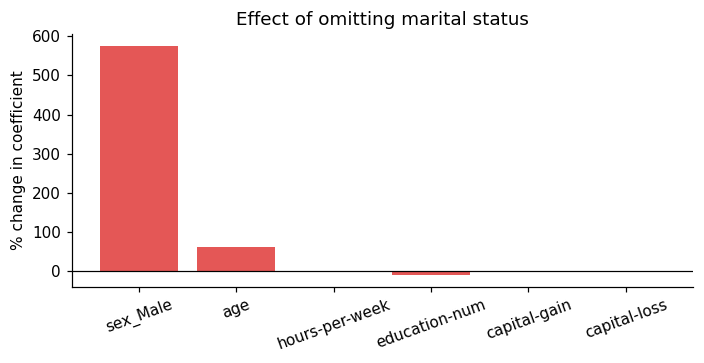

In [7]:
E_train_reduced = E_train.drop(columns=marital_cols)
reduced_logit = fit_logit(E_train_reduced, y_train)

shift = pd.DataFrame({'full': full_logit.coef, 'reduced': reduced_logit.coef}).dropna().drop(index='const')
shift['chg'] = shift['reduced'] - shift['full']
shift['pct'] = shift['chg'] / shift['full'].abs() * 100
shift['abs_pct'] = shift['pct'].abs()

tracked = ['sex_Male', 'age', 'hours-per-week', 'education-num', 'capital-gain', 'capital-loss']
by_abs_change = shift.reindex(shift['chg'].abs().sort_values(ascending=False).index).head(5)

ovb = {
    'dropped': 'marital-status (5 dummies)',
    'table': [
        {'predictor': p, 'full': float(shift.loc[p, 'full']), 'reduced': float(shift.loc[p, 'reduced']),
         'abs_change': float(shift.loc[p, 'chg']), 'pct_change': float(shift.loc[p, 'pct'])}
        for p in tracked
    ],
    'top_pct': [
        {'predictor': name, 'full': float(row['full']), 'reduced': float(row['reduced']), 'pct_change': float(row['pct'])}
        for name, row in shift.sort_values('abs_pct', ascending=False).head(6).iterrows()
    ],
    'top_abs': [
        {'predictor': name, 'full': float(row['full']), 'reduced': float(row['reduced']), 'abs_change': float(row['chg'])}
        for name, row in by_abs_change.iterrows()
    ],
}

pred_reduced = predict_logit(reduced_logit, E_test.drop(columns=marital_cols))
ovb['acc_full'] = float(((pred_logit >= .5) == y_true).mean())
ovb['acc_reduced'] = float(((pred_reduced >= .5) == y_true).mean())
ovb['auc_full'] = float(roc_auc_score(y_true, pred_logit))
ovb['auc_reduced'] = float(roc_auc_score(y_true, pred_reduced))

married_test = raw_test['marital-status'].isin(['Married-civ-spouse', 'Married-AF-spouse']).values
resid_reduced = y_true - pred_reduced
resid_full = y_true - pred_logit
ovb['resid_corr_married_reduced'] = float(np.corrcoef(resid_reduced, married_test)[0, 1])
ovb['resid_corr_married_full'] = float(np.corrcoef(resid_full, married_test)[0, 1])
ovb['calib'] = {
    group: {'obs': float(y_true[m].mean()),
            'pred_reduced': float(pred_reduced[m].mean()),
            'pred_full': float(pred_logit[m].mean())}
    for group, m in (('married', married_test), ('unmarried', ~married_test))
}
results['ovb'] = ovb

print(shift.loc[tracked, ['full', 'reduced', 'chg', 'pct']].round(3), '\n')
print('Largest % shifts:')
print(shift.sort_values('abs_pct', ascending=False).head(6)[['full', 'reduced', 'pct']].round(3))
print('\nAggregate metrics full vs reduced: acc %.4f vs %.4f | AUC %.4f vs %.4f' % (ovb['acc_full'], ovb['acc_reduced'], ovb['auc_full'], ovb['auc_reduced']))
print('Residual correlation with married flag (test): reduced %.3f, full %.3f' % (ovb['resid_corr_married_reduced'], ovb['resid_corr_married_full']))
print('Calibration by marital group:', ovb['calib'])

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar([r['predictor'] for r in ovb['table']], [r['pct_change'] for r in ovb['table']], color='#E45756')
ax.axhline(0, color='k', lw=.8)
ax.set_ylabel('% change in coefficient')
ax.set_title('Effect of omitting marital status')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('figures/fig3_ovb.png', dpi=150)
plt.show()

{'n_test': 9769, 'n_fp': 115, 'n_fn': 411, 'n_total': 526, 'pct_total': 5.3843791585628, 'n_sample': 50, 'sample_fp': 10, 'sample_fn': 40, 'n_pred_ge75': 833, 'n_pred_le25': 6369, 'fp_rate_among_ge75_pct': 13.805522208883552, 'fn_rate_among_le25_pct': 6.4531323598681105, 'age': {'sample_mean': 45.06, 'sample_median': 42.0, 'test_mean': 38.68154365851162, 'test_median': 37.0}, 'hours': {'sample_mean': 41.06, 'test_mean': 40.340362370764666}, 'edu': {'sample_mean': 10.56, 'test_mean': 10.053843791585628}, 'marital_wrong_way_sample_pct': 60.0, 'marital_wrong_way_all_pct': 61.78707224334601, 'fp_married_pct': 99.1304347826087, 'fn_unmarried_pct': 51.338199513382, 'positives_unmarried_pct': 15.175922000847816, 'correct_positives_unmarried_pct': 7.546201232032853, 'fn_zero_capgain_pct': 94.16058394160584, 'fn_mean_edu': 10.085158150851582, 'tp_mean_edu': 11.937371663244353, 'fp_mean_edu': 12.878260869565217, 'fp_male_pct': 95.65217391304348, 'marital_coefs': {'Divorced': -2.0683130099219538,

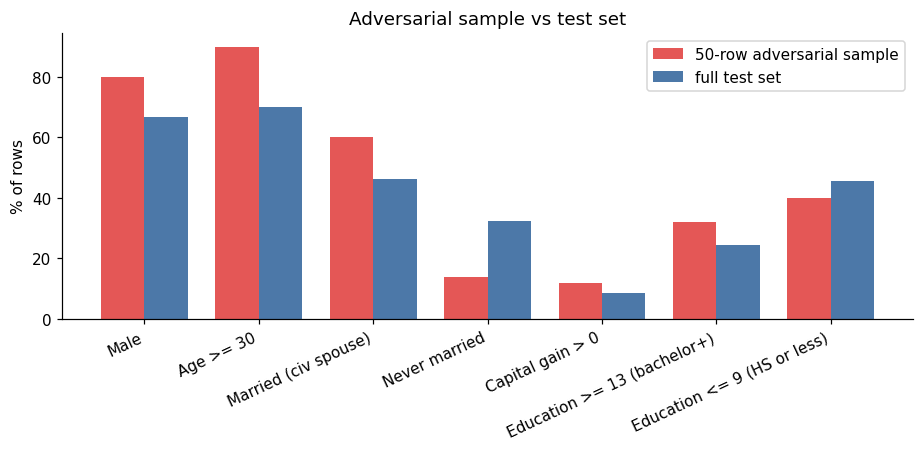

In [8]:
conf_fp = (pred_logit >= 0.75) & (y_true == 0)
conf_fn = (pred_logit <= 0.25) & (y_true == 1)
wrong_idx = np.where(conf_fp | conf_fn)[0]

if len(wrong_idx) > 50:
    sample_idx = np.random.RandomState(SEED).choice(wrong_idx, 50, replace=False)
else:
    sample_idx = wrong_idx

adv = {
    'n_test': int(len(y_true)),
    'n_fp': int(conf_fp.sum()),
    'n_fn': int(conf_fn.sum()),
    'n_total': int(len(wrong_idx)),
    'pct_total': float(len(wrong_idx) / len(y_true) * 100),
    'n_sample': int(len(sample_idx)),
    'sample_fp': int(conf_fp[sample_idx].sum()),
    'sample_fn': int(conf_fn[sample_idx].sum()),
}
adv['n_pred_ge75'] = int((pred_logit >= .75).sum())
adv['n_pred_le25'] = int((pred_logit <= .25).sum())
adv['fp_rate_among_ge75_pct'] = float(adv['n_fp'] / adv['n_pred_ge75'] * 100)
adv['fn_rate_among_le25_pct'] = float(adv['n_fn'] / adv['n_pred_le25'] * 100)

def profile_flags(r):
    civ_married = r['marital-status'].isin(['Married-civ-spouse', 'Married-AF-spouse'])
    return pd.DataFrame({
        'Male': r.sex == 'Male',
        'White': r.race == 'White',
        'Age >= 40': r.age >= 40,
        'Age < 30': r.age < 30,
        'Age >= 30': r.age >= 30,
        'Married (civ spouse)': civ_married,
        'Never married': r['marital-status'] == 'Never-married',
        'Capital gain > 0': r['capital-gain'] > 0,
        'Hours >= 45': r['hours-per-week'] >= 45,
        'Hours < 35': r['hours-per-week'] < 35,
        'Education >= 13 (bachelor+)': r['education-num'] >= 13,
        'Education <= 9 (HS or less)': r['education-num'] <= 9,
        'Exec/Prof occupation': r.occupation.isin(['Exec-managerial', 'Prof-specialty']),
        'US-born': r['native-country'] == 'United-States',
    })

flags = profile_flags(raw_test)
profile = pd.DataFrame({
    'sample50_%': flags.iloc[sample_idx].mean() * 100,
    'full_test_%': flags.mean() * 100,
})
profile['diff_pp'] = profile['sample50_%'] - profile['full_test_%']
profile['fp_rows_%'] = flags[conf_fp].mean() * 100
profile['fn_rows_%'] = flags[conf_fn].mean() * 100
adv['flag_table'] = {name: {k: float(v) for k, v in row.items()} for name, row in profile.iterrows()}

adv['age'] = {
    'sample_mean': float(raw_test.age.values[sample_idx].mean()),
    'sample_median': float(np.median(raw_test.age.values[sample_idx])),
    'test_mean': float(raw_test.age.mean()),
    'test_median': float(raw_test.age.median()),
}
adv['hours'] = {
    'sample_mean': float(raw_test['hours-per-week'].values[sample_idx].mean()),
    'test_mean': float(raw_test['hours-per-week'].mean()),
}
adv['edu'] = {
    'sample_mean': float(raw_test['education-num'].values[sample_idx].mean()),
    'test_mean': float(raw_test['education-num'].mean()),
}

married_flag = flags['Married (civ spouse)'].values
pushed_wrong_way = (conf_fp & married_flag) | (conf_fn & ~married_flag)
adv['marital_wrong_way_sample_pct'] = float(pushed_wrong_way[sample_idx].mean() * 100)
adv['marital_wrong_way_all_pct'] = float(pushed_wrong_way[wrong_idx].mean() * 100)
adv['fp_married_pct'] = float(married_flag[conf_fp].mean() * 100)
adv['fn_unmarried_pct'] = float((~married_flag[conf_fn]).mean() * 100)

positives = y_true == 1
adv['positives_unmarried_pct'] = float((~married_flag[positives]).mean() * 100)
adv['correct_positives_unmarried_pct'] = float((~married_flag[positives & ~conf_fn]).mean() * 100)
adv['fn_zero_capgain_pct'] = float((~flags['Capital gain > 0'].values[conf_fn]).mean() * 100)
adv['fn_mean_edu'] = float(raw_test['education-num'].values[conf_fn].mean())
adv['tp_mean_edu'] = float(raw_test['education-num'].values[positives & ~conf_fn].mean())
adv['fp_mean_edu'] = float(raw_test['education-num'].values[conf_fp].mean())
adv['fp_male_pct'] = float(flags['Male'].values[conf_fp].mean() * 100)

marital_coefs = full_logit.loc[marital_cols, 'coef']
adv['marital_coefs'] = {k.replace('marital-status_', ''): float(v) for k, v in marital_coefs.items()}
adv['marital_odds_never'] = float(np.exp(full_logit.loc['marital-status_Never-married', 'coef']))
adv['coef_sex'] = float(full_logit.loc['sex_Male', 'coef'])

def add_terms(E, mode):
    out = E.copy()
    married_col = 1 - E[marital_cols].sum(axis=1)
    out['married'] = married_col
    if mode in ('inter', 'both'):
        for col in ['age', 'education-num', 'hours-per-week', 'capital-gain', 'capital-loss', 'sex_Male']:
            out[col + '_x_married'] = E[col] * married_col
    if mode in ('quad', 'both'):
        out['age2'] = E['age'] ** 2
    return out

def count_confident_errors(p):
    return int(((p >= .75) & (y_true == 0)).sum() + ((p <= .25) & (y_true == 1)).sum())

adv['diag'] = {'base': count_confident_errors(pred_logit)}
for mode in ('inter', 'quad', 'both'):
    extended = fit_logit(add_terms(E_train, mode), y_train)
    p_ext = predict_logit(extended, add_terms(E_test, mode))
    adv['diag'][mode] = {
        'n_conf': count_confident_errors(p_ext),
        'acc': float(((p_ext >= .5) == y_true).mean()),
    }
adv['diag']['base_acc'] = float(((pred_logit >= .5) == y_true).mean())
results['adv'] = adv

print({k: v for k, v in adv.items() if k not in ('flag_table',)})
print(profile.round(1).sort_values('diff_pp', key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
shown = ['Male', 'Age >= 30', 'Married (civ spouse)', 'Never married', 'Capital gain > 0',
         'Education >= 13 (bachelor+)', 'Education <= 9 (HS or less)']
xpos = np.arange(len(shown))
width = .38
ax.bar(xpos - width / 2, profile.loc[shown, 'sample50_%'], width, label='50-row adversarial sample', color='#E45756')
ax.bar(xpos + width / 2, profile.loc[shown, 'full_test_%'], width, label='full test set', color='#4C78A8')
ax.set_xticks(xpos)
ax.set_xticklabels(shown, rotation=25, ha='right')
ax.set_ylabel('% of rows')
ax.set_title('Adversarial sample vs test set')
ax.legend()
plt.tight_layout()
plt.savefig('figures/fig4_adversarial.png', dpi=150)
plt.show()

   t    DP    EO    PP   acc  selA  selB  tprA  tprB  fprA  fprB
0.05 0.593 0.598 0.595 0.609 0.427 0.720 0.956 0.985 0.361 0.603
0.15 0.350 0.303 0.895 0.755 0.198 0.566 0.803 0.931 0.122 0.404
0.25 0.286 0.222 1.003 0.809 0.130 0.456 0.673 0.853 0.062 0.281
0.35 0.249 0.184 1.031 0.837 0.090 0.362 0.537 0.759 0.034 0.187
0.45 0.228 0.152 1.063 0.845 0.066 0.291 0.440 0.662 0.019 0.128
0.55 0.204 0.101 1.126 0.845 0.047 0.233 0.357 0.566 0.009 0.086
0.65 0.165 0.093 1.065 0.838 0.029 0.176 0.224 0.463 0.005 0.048
0.75 0.139 0.071 1.057 0.820 0.017 0.119 0.136 0.335 0.002 0.024
0.85 0.135 0.000 1.099 0.798 0.009 0.066 0.080 0.197 0.000 0.009
0.95 0.067 0.000 1.026 0.771 0.001 0.018 0.011 0.059 0.000 0.001

 {'t_best_PP': 0.25, 't_best_DP': 0.05, 't_best_EO': 0.05, 't_best_acc': 0.45, 'DP_from': 0.2856674670159979, 'DP_to': 0.59257534714628, 'EO_from': 0.2220775652264936, 'EO_to': 0.5976279943993326, 'PP_from': 1.0030448617957197, 'PP_to': 0.5947708461741656, 'acc_from': 0.8092947077490

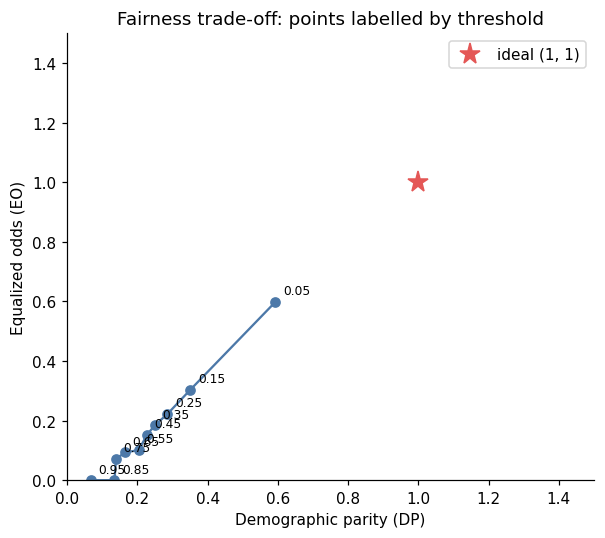

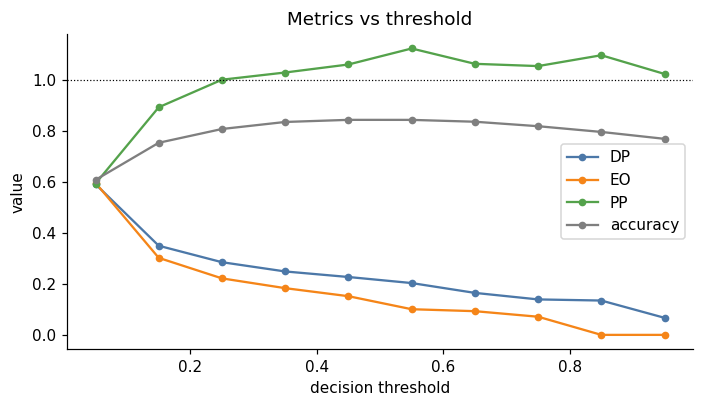

In [9]:
sex_test = raw_test.sex.values
group_a = sex_test == 'Female'
group_b = ~group_a

def safe_ratio(a, b):
    if b is None or np.isnan(b) or b <= 0 or np.isnan(a):
        return float('nan')
    return float(a / b)

def group_rate(group, y_hat, condition=None):
    mask = group if condition is None else group & condition
    return float(y_hat[mask].mean()) if mask.sum() > 0 else float('nan')

thresholds = np.round(np.arange(0.05, 0.951, 0.1), 2)
rows = []
for t in thresholds:
    y_hat = (pred_logit >= t).astype(int)

    sel_a, sel_b = group_rate(group_a, y_hat), group_rate(group_b, y_hat)
    tpr_a, tpr_b = group_rate(group_a, y_hat, y_true == 1), group_rate(group_b, y_hat, y_true == 1)
    fpr_a, fpr_b = group_rate(group_a, y_hat, y_true == 0), group_rate(group_b, y_hat, y_true == 0)

    flagged_a = group_a & (y_hat == 1)
    flagged_b = group_b & (y_hat == 1)
    ppv_a = float(y_true[flagged_a].mean()) if flagged_a.sum() > 0 else float('nan')
    ppv_b = float(y_true[flagged_b].mean()) if flagged_b.sum() > 0 else float('nan')

    tpr_ratio = safe_ratio(tpr_a, tpr_b)
    fpr_ratio = safe_ratio(fpr_a, fpr_b)
    both_missing = np.isnan(tpr_ratio) and np.isnan(fpr_ratio)
    eo = float('nan') if both_missing else float(np.nanmin([tpr_ratio, fpr_ratio]))

    rows.append({
        't': float(t),
        'DP': safe_ratio(sel_a, sel_b),
        'EO': eo,
        'PP': safe_ratio(ppv_a, ppv_b),
        'acc': float((y_hat == y_true).mean()),
        'accA': float((y_hat[group_a] == y_true[group_a]).mean()),
        'accB': float((y_hat[group_b] == y_true[group_b]).mean()),
        'selA': sel_a, 'selB': sel_b,
        'tprA': tpr_a, 'tprB': tpr_b,
        'fprA': fpr_a, 'fprB': fpr_b,
        'ppvA': ppv_a, 'ppvB': ppv_b,
        'tpr_ratio': tpr_ratio,
        'fpr_ratio': fpr_ratio,
        'n_pos': int(y_hat.sum()),
    })

fair = pd.DataFrame(rows)
print(fair[['t', 'DP', 'EO', 'PP', 'acc', 'selA', 'selB', 'tprA', 'tprB', 'fprA', 'fprB']].round(3).to_string(index=False))
results['fair'] = {
    'table': rows,
    'n_female_test': int(group_a.sum()),
    'n_male_test': int(group_b.sum()),
    'pos_rate_female': float(y_true[group_a].mean()),
    'pos_rate_male': float(y_true[group_b].mean()),
}

by_t = fair.set_index('t')
t_best_pp = float((by_t.PP - 1).abs().idxmin())
t_best_dp = float(by_t.DP.idxmax())
t_best_acc = float(by_t.acc.idxmax())

def pct_change(a, b):
    return float((b - a) / a * 100)

tradeoff = {
    't_best_PP': t_best_pp,
    't_best_DP': t_best_dp,
    't_best_EO': float(by_t.EO.idxmax()),
    't_best_acc': t_best_acc,
    'DP_from': float(by_t.loc[t_best_pp, 'DP']),
    'DP_to': float(by_t.loc[t_best_dp, 'DP']),
    'EO_from': float(by_t.loc[t_best_pp, 'EO']),
    'EO_to': float(by_t.loc[t_best_dp, 'EO']),
    'PP_from': float(by_t.loc[t_best_pp, 'PP']),
    'PP_to': float(by_t.loc[t_best_dp, 'PP']),
    'acc_from': float(by_t.loc[t_best_pp, 'acc']),
    'acc_to': float(by_t.loc[t_best_dp, 'acc']),
}
tradeoff['DP_gain_pct'] = pct_change(tradeoff['DP_from'], tradeoff['DP_to'])
tradeoff['EO_gain_pct'] = pct_change(tradeoff['EO_from'], tradeoff['EO_to'])
tradeoff['PP_gap_from'] = abs(1 - tradeoff['PP_from'])
tradeoff['PP_gap_to'] = abs(1 - tradeoff['PP_to'])
tradeoff['PP_loss_pct_pts'] = (tradeoff['PP_gap_to'] - tradeoff['PP_gap_from']) * 100
tradeoff['acc_loss_pct'] = -pct_change(tradeoff['acc_from'], tradeoff['acc_to'])
tradeoff['cost_acc_per_DP'] = tradeoff['acc_loss_pct'] / tradeoff['DP_gain_pct']
tradeoff['cost_PP_per_DP'] = (tradeoff['PP_gap_to'] - tradeoff['PP_gap_from']) * 100 / tradeoff['DP_gain_pct']

conflicts = []
for a, b in zip(thresholds[:-1], thresholds[1:]):
    dp_up_eo_down = by_t.loc[b, 'DP'] > by_t.loc[a, 'DP'] and by_t.loc[b, 'EO'] < by_t.loc[a, 'EO']
    dp_down_eo_up = by_t.loc[b, 'DP'] < by_t.loc[a, 'DP'] and by_t.loc[b, 'EO'] > by_t.loc[a, 'EO']
    if dp_up_eo_down or dp_down_eo_up:
        conflicts.append((float(a), float(b)))
tradeoff['dp_eo_conflicts'] = conflicts
tradeoff['corr_DP_EO'] = float(by_t[['DP', 'EO']].dropna().corr().iloc[0, 1])
results['fair']['tradeoff'] = tradeoff
print('\n', tradeoff)

fig, ax = plt.subplots(figsize=(5.6, 5))
ax.plot(fair.DP, fair.EO, '-o', color='#4C78A8')
for _, r in fair.iterrows():
    ax.annotate(f"{r.t:.2f}", (r.DP, r.EO), textcoords='offset points', xytext=(5, 5), fontsize=8)
ax.plot([1], [1], marker='*', ms=14, color='#E45756', ls='', label='ideal (1, 1)')
ax.set_xlim(0, 1.5)
ax.set_ylim(0, 1.5)
ax.set_xlabel('Demographic parity (DP)')
ax.set_ylabel('Equalized odds (EO)')
ax.set_title('Fairness trade-off: points labelled by threshold')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('figures/fig5_tradeoff.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for col, color in (('DP', '#4C78A8'), ('EO', '#F58518'), ('PP', '#54A24B'), ('acc', '#7F7F7F')):
    ax.plot(fair.t, fair[col], '-o', ms=4, label=col if col != 'acc' else 'accuracy', color=color)
ax.axhline(1, color='k', ls=':', lw=.8)
ax.set_xlabel('decision threshold')
ax.set_ylabel('value')
ax.legend()
ax.set_title('Metrics vs threshold')
plt.tight_layout()
plt.savefig('figures/fig6_metrics_vs_threshold.png', dpi=150)
plt.show()

In [10]:
candidates = raw_test.assign(p=pred_logit, y=y_true, row=np.arange(len(y_true)), mc=married_test)
candidates = candidates[candidates.y == 1]
women = candidates[candidates.sex == 'Female']
men = candidates[candidates.sex == 'Male']

pairs = []
for _, w in women.iterrows():
    similar = men[(men['education-num'] == w['education-num'])
                  & (men.occupation == w.occupation)
                  & (men.mc == w.mc)
                  & ((men.age - w.age).abs() <= 3)
                  & ((men['hours-per-week'] - w['hours-per-week']).abs() <= 5)]
    for _, m in similar.iterrows():
        pairs.append((w.row, m.row, m.p - w.p))

pairs = pd.DataFrame(pairs, columns=['f_row', 'm_row', 'gap'])
median_gap = pairs.gap.median()
chosen = pairs.iloc[(pairs.gap - median_gap).abs().argmin()]
woman_row, man_row = int(chosen.f_row), int(chosen.m_row)

def describe(i):
    r = raw_test.iloc[i]
    return {
        'row': int(i),
        'age': int(r.age),
        'edu_num': int(r['education-num']),
        'occupation': r.occupation,
        'marital': r['marital-status'],
        'hours': int(r['hours-per-week']),
        'capital_gain': int(r['capital-gain']),
        'p': float(pred_logit[i]),
    }

pair_info = {
    'n_pairs': int(len(pairs)),
    'median_gap': float(median_gap),
    'woman': describe(woman_row),
    'man': describe(man_row),
    'gap': float(chosen.gap),
}
pair_info['outcomes'] = {
    str(t): {'woman_flag': int(pred_logit[woman_row] >= t), 'man_flag': int(pred_logit[man_row] >= t)}
    for t in (0.05, 0.25, 0.45, 0.65)
}
results['pair'] = pair_info
print(pair_info)

{'n_pairs': 1041, 'median_gap': 0.052227963088353646, 'woman': {'row': 8015, 'age': 42, 'edu_num': 10, 'occupation': 'Exec-managerial', 'marital': 'Married-civ-spouse', 'hours': 40, 'capital_gain': 0, 'p': 0.4317957650164134}, 'man': {'row': 9098, 'age': 44, 'edu_num': 10, 'occupation': 'Exec-managerial', 'marital': 'Married-civ-spouse', 'hours': 40, 'capital_gain': 0, 'p': 0.48402372810476707}, 'gap': 0.052227963088353646, 'outcomes': {'0.05': {'woman_flag': 1, 'man_flag': 1}, '0.25': {'woman_flag': 1, 'man_flag': 1}, '0.45': {'woman_flag': 0, 'man_flag': 1}, '0.65': {'woman_flag': 0, 'man_flag': 0}}}


In [11]:
def to_plain(obj):
    if isinstance(obj, dict):
        return {str(k): to_plain(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_plain(v) for v in obj]
    if isinstance(obj, (np.floating, float)):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj

results['full_model_table'] = {
    name: {k: float(v) for k, v in row.items()} for name, row in full_logit.iterrows()
}

with open('results.json', 'w') as fh:
    json.dump(to_plain(results), fh, indent=1)
print('results.json written with', len(results), 'top-level keys; figures:', sorted(os.listdir('figures')))

results.json written with 26 top-level keys; figures: ['fig1_predictions.png', 'fig2_simpson.png', 'fig3_ovb.png', 'fig4_adversarial.png', 'fig5_tradeoff.png', 'fig6_metrics_vs_threshold.png']
